# H4 — Terminal descent, fuel and bounded reachability

This notebook runs the repository's physical model. It is the **classical validation foundation**
for later hybrid recovery; it makes **no quantum or provider calls**.

We will inspect: (1) explicit state and units, (2) a fuel-exhaustion regression,
(3) nominal descent, (4) rejected cases, (5) candidate reachability at two time steps,
and (6) restart from a saved state.

**Scope:** spherical point-mass Moon, nonrotating planar coordinates, constant specific impulse,
instantaneous thrust direction changes, and a declared piecewise-linear 2D terrain corridor.
The example vehicle and terrain are synthetic. Numerical consistency is not real-flight validation.

In [1]:
from pathlib import Path
from copy import deepcopy
from html import escape
import json
import math
import os
import sys
import numpy as np
from IPython.display import HTML, SVG, display
start = Path(os.environ.get("LUNAR_REPO_ROOT", Path.cwd())).resolve()
roots = [start, *start.parents, start / "quantum-hybrid-workspace", start / "h0-hybrid-workspace"]
ROOT = next((p for p in roots if (p / "backend/app/terminal_descent.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open from the repository or set LUNAR_REPO_ROOT.")
sys.path.insert(0, str(ROOT))
from backend.app.terminal_descent import TerminalRequest, LandingTarget, simulate_terminal, evaluate_targets, vehicle_from_r4
from backend.app.descent_dynamics import advance_burn
from shared.hybrid import Source
from shared.constants import MOON_REFERENCE_RADIUS_M as R, STANDARD_GRAVITY_M_S2 as G0, POUND_FORCE_N, POUND_MASS_KG
import backend.app.terminal_descent as terminal_module
assert Path(terminal_module.__file__).resolve() == ROOT / "backend/app/terminal_descent.py"
def table(headers, rows):
    def row(values, tag):
        return "<tr>" + "".join(f"<{tag}>{escape(str(v))}</{tag}>" for v in values) + "</tr>"
    display(HTML("<table>" + row(headers, "th") + "".join(row(r, "td") for r in rows) + "</table>"))
print("Loaded the repository model; local execution only.")

Loaded the repository model; local execution only.


## 1. Read the complete request

Position and velocity use two Moon-centred coordinates. At downrange zero, +y points up
and +x points forward. Altitude is radius minus the declared terrain reference radius.
This is **not the rotating 3D MOON_ME state in H0**; no automatic conversion is implied.
The UTC epoch, vehicle identity, state revision and remaining propellant are explicit.

In [2]:
raw = json.loads((ROOT / "shared/examples/descent/terminal_nominal.json").read_text())
job = TerminalRequest.model_validate(raw)
table(["Input", "Value"], [
    ["Frame", job.initial_state.reference_frame],
    ["Epoch (UTC)", job.initial_state.epoch_utc.isoformat()],
    ["Position (m)", job.initial_state.position_m],
    ["Velocity (m/s)", job.initial_state.velocity_mps],
    ["Dry mass / fuel (kg)", (job.vehicle.dry_mass_kg, job.initial_state.propellant_kg)],
    ["Required reserve (kg)", job.reserve_kg],
    ["Terrain origin", job.terrain.source.description],
])

Input,Value
Frame,PLANAR_MOON_CENTERED_NONROTATING
Epoch (UTC),2030-01-01T00:00:00+00:00
Position (m),"(0.0, 1737500.0)"
Velocity (m/s),"(0.0, -3.0)"
Dry mass / fuel (kg),"(900.0, 100.0)"
Required reserve (kg),10.0
Terrain origin,Illustrative flat corridor and 1000 kg vehicle. Not a real landing site or calibrated spacecraft.


## 2. Reuse the sourced R4 engine profile

R4 stores Apollo values in their published units. Convert those inputs to SI and use the
same H4 adapter tested against `load_profiles()`. This displays engine compatibility;
it does **not** infer Apollo's fuel or velocity at a new terminal starting point.
The descent demo below continues to use the explicitly synthetic vehicle.

In [3]:
profiles = json.loads((ROOT / "shared/vehicle_profiles.json").read_text())
published = next(p for p in profiles["profiles"] if p["profile_id"] == "apollo-lm-11")
si_profile = {
    "profile_id": published["profile_id"],
    "mass_at_pdi_kg": published["mass_at_pdi_lb"] * POUND_MASS_KG,
    "usable_propellant_kg": published["usable_propellant_lb"] * POUND_MASS_KG,
    "max_thrust_n": published["max_thrust_lbf"] * POUND_FORCE_N,
    "design_thrust_n": published["design_thrust_lbf"] * POUND_FORCE_N,
    **{k: published[k] for k in ("min_throttle_fraction", "max_throttle_fraction", "isp_s")},
}
apollo = vehicle_from_r4(si_profile, source=Source(
    source_id="r4-apollo-profile", kind="derived", description="SI conversion of the repository's sourced Apollo 11 PDI profile.",
    locator="shared/vehicle_profiles.json", version="r4-si-conversion-v1",
    parent_source_ids=("apollo-11-published-profile",)))
table(["R4-compatible input", "SI value"], [
    ["Dry mass (kg)", round(apollo.dry_mass_kg, 3)],
    ["PDI usable propellant (kg)", round(apollo.propellant_capacity_kg, 3)],
    ["Maximum thrust (N)", round(apollo.max_thrust_n, 3)], ["Specific impulse (s)", apollo.isp_s],
])

R4-compatible input,SI value
Dry mass (kg),6989.45
PDI usable propellant (kg),8161.261
Maximum thrust (N),44482.216
Specific impulse (s),309.7


## 3. Fuel must end thrust inside a time step

The analytic zero-gravity reference is `Isp * g0 * ln(initial mass / final mass)`.
With only 1 kg remaining, a 500 kN command cannot continue for the entire 0.1 s step.
The integrator burns to exhaustion and coasts for the remaining time. The same integrator
now serves R4/R5. A frozen regression test checks the former R4 excess-impulse case.

In [4]:
probe = advance_burn((0., R), (0., 0.), 1000., 999., (0., 500000.), 300., .1, gm_m3_s2=0.)
expected_dv = 300 * G0 * math.log(1000 / 999)
assert abs(probe.velocity_mps[1] - expected_dv) < 1e-7
assert probe.mass_kg == 999 and probe.propellant_exhausted
table(["Quantity", "Measured"], [
    ["Burn time (s)", probe.burn_s], ["Coast time (s)", probe.coast_s],
    ["Analytic delta-v (m/s)", expected_dv], ["Integrated delta-v (m/s)", probe.velocity_mps[1]],
    ["Final mass (kg)", probe.mass_kg],
])

Quantity,Measured
Burn time (s),0.0058839899999999995
Coast time (s),0.09411601
Analytic delta-v (m/s),2.943466978901348
Integrated delta-v (m/s),2.9434669789011116
Final mass (kg),999.0


## 4. Run the terminal descent

The engine follows the existing R4 throttle rule. Position, speed, terrain slope and reserve
are checked at the first detected contact. An earlier high-speed collision is a failed landing,
even if the original deadline has not been reached. `feasible` means only that the declared
model's limits pass. A missed deadline is never treated as touchdown.

In [5]:
nominal = simulate_terminal(job)
final = nominal["trace"][-1]
assert nominal["feasible"] and nominal["termination"] == "contact"
table(["Nominal result", "Value"], [
    ["Feasible under declared model", nominal["feasible"]], ["Time (s)", final["t_s"]],
    ["Downrange error (m)", final["downrange_m"] - job.target_downrange_m],
    ["Vertical speed (m/s)", final["vertical_speed_mps"]],
    ["Horizontal speed (m/s)", final["horizontal_speed_mps"]],
    ["Fuel used (kg)", nominal["propellant_used_kg"]],
    ["Remaining fuel (kg)", nominal["propellant_remaining_kg"]],
    ["Reserve margin (kg)", nominal["reserve_margin_kg"]],
])

Nominal result,Value
Feasible under declared model,True
Time (s),29.9999533476308
Downrange error (m),0.0
Vertical speed (m/s),-0.500258471292985
Horizontal speed (m/s),0.0
Fuel used (kg),17.26053978243374
Remaining fuel (kg),82.73946021756626
Reserve margin (kg),72.73946021756626


## 5. Inspect altitude and fuel over time

These plots display the model's stored trace. They do not calculate flight dynamics.
Fuel decreases monotonically; the reserve line is a hard acceptance threshold, not an engine cutoff.

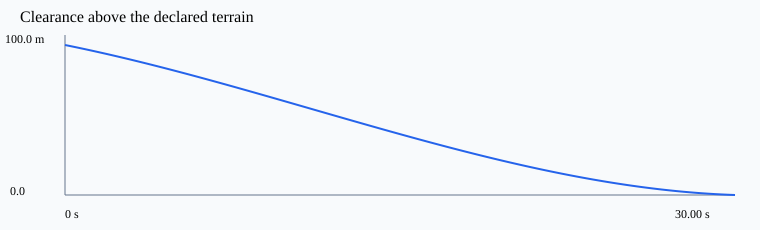

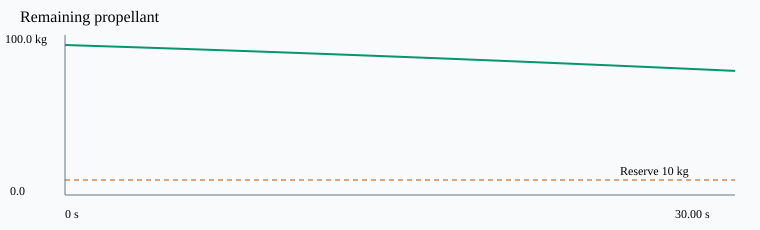

In [6]:
def plot_trace(title, times, values, color, unit, reference=None):
    width, height, left, top = 760, 230, 65, 35
    low = min(0., min(values), reference if reference is not None else 0.)
    high = max(max(values), reference if reference is not None else 0., 1.)
    def x(t): return left + t / max(times[-1], 1.) * (width - left - 25)
    def y(v): return height - 35 - (v - low) / (high - low) * (height - top - 45)
    points = " ".join(f"{x(t):.3f},{y(v):.3f}" for t, v in zip(times, values))
    line = "" if reference is None else f'<line x1="{left}" y1="{y(reference)}" x2="{width-25}" y2="{y(reference)}" stroke="#b45309" stroke-dasharray="5 4"/><text x="{width-140}" y="{y(reference)-5}" font-size="12">Reserve {reference:g} {unit}</text>'
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}"><rect width="100%" height="100%" fill="#f8fafc"/><text x="20" y="22" font-size="16">{escape(title)}</text><line x1="{left}" y1="{top}" x2="{left}" y2="{height-35}" stroke="#64748b"/><line x1="{left}" y1="{height-35}" x2="{width-25}" y2="{height-35}" stroke="#64748b"/><text x="5" y="{top+8}" font-size="12">{high:.1f} {unit}</text><text x="10" y="{height-35}" font-size="12">{low:.1f}</text><text x="{left}" y="{height-12}" font-size="12">0 s</text><text x="{width-85}" y="{height-12}" font-size="12">{times[-1]:.2f} s</text>{line}<polyline points="{points}" fill="none" stroke="{color}" stroke-width="2"/></svg>'))
times = [r["t_s"] for r in nominal["trace"]]
plot_trace("Clearance above the declared terrain", times, [r["clearance_m"] for r in nominal["trace"]], "#2563eb", "m")
plot_trace("Remaining propellant", times, [r["state"]["propellant_kg"] for r in nominal["trace"]], "#059669", "kg", job.reserve_kg)

## 6. Deliberately fail the constraints

The same execution path handles fuel loss, insufficient thrust, an excessive reserve demand,
a steep landing surface and missing coverage. These are separate deterministic input cases,
not an H5 fault-event replay or a sensor uncertainty model.

In [7]:
variants = {}
low_fuel = deepcopy(raw); low_fuel["initial_state"]["propellant_kg"] = .01
variants["Nearly empty tank"] = low_fuel
low_thrust = deepcopy(raw); low_thrust["vehicle"].update(max_thrust_n=100., design_thrust_n=100.)
variants["Insufficient thrust"] = low_thrust
reserve = deepcopy(raw); reserve["reserve_kg"] = 99.
variants["Reserve violation"] = reserve
steep = deepcopy(raw); steep["terrain"]["points"] = [{"downrange_m":-100., "height_m":-100.}, {"downrange_m":100., "height_m":100.}]
variants["Steep surface"] = steep
unknown = deepcopy(raw); unknown["target_downrange_m"] = 30000.
variants["Unknown target terrain"] = unknown
failures = {name: simulate_terminal(TerminalRequest.model_validate(value)) for name, value in variants.items()}
assert all(not result["feasible"] for result in failures.values())
table(["Case", "Termination", "Reasons", "Fuel left (kg)"], [
    [name, result["termination"], ", ".join(result["reasons"]), round(result["propellant_remaining_kg"], 6)]
    for name, result in failures.items()
])

Case,Termination,Reasons,Fuel left (kg)
Nearly empty tank,contact,"vertical_speed, reserve",0.0
Insufficient thrust,contact,vertical_speed,99.671823
Reserve violation,contact,reserve,82.73946
Steep surface,contact,terrain_slope,82.73946
Unknown target terrain,terrain_unknown,terrain_coverage,100.0


## 7. Evaluate only explicit landing candidates

Try five nearby points and one unreachable fast diversion. Every candidate is replayed at
`dt` and `dt/2`. Both must satisfy the flight limits and agree within 0.5 m, 0.1 m/s,
0.05 kg and 0.2 s. Select the least-fuel accepted candidate; retain all rejected results.
This is a finite candidate check, **not a global reachability envelope or guaranteed optimum**.

In [8]:
targets = tuple(LandingTarget(target_id=f"point-{i}", downrange_m=float(i), duration_s=30.) for i in (-100, -20, 0, 20, 100)) + (LandingTarget(target_id="far-fast", downrange_m=10000., duration_s=5.),)
assessment = evaluate_targets(job, targets)
assert assessment["recommended_target_id"] == "point-0"
assert not assessment["candidates"][-1]["reachable"]
table(["Target", "Reachable", "Fuel used (kg, fine)", "Delta fuel (kg)", "Fine rejection reasons"], [
    [c["target_id"], c["reachable"], round(c["fine"]["propellant_used_kg"], 6), round(c["fuel_difference_kg"], 8), ", ".join(c["fine"]["reasons"])]
    for c in assessment["candidates"]
])
print("Recommended:", assessment["recommended_target_id"])

Target,Reachable,"Fuel used (kg, fine)",Delta fuel (kg),Fine rejection reasons
point--100,True,17.693682,0.00030698,
point--20,True,17.278248,4.797e-05,
point-0,True,17.260504,3.623e-05,
point-20,True,17.278248,4.797e-05,
point-100,True,17.693682,0.00030698,
far-fast,False,16.99527,0.0,no_contact


Recommended: point-0


## 8. Restart from a saved state

At 5 seconds, reuse the actual position, velocity, UTC epoch and remaining fuel.
The controller is recomputed for the remaining time; no fuel is replenished.
Restart is state-based, not a byte-identical controller checkpoint: the last held guidance
command is not serialized, so a restart in the final hold interval may differ.

In [9]:
checkpoint = nominal["trace"][50]
restart_data = deepcopy(raw)
restart_data["initial_state"] = checkpoint["state"]
restart_data["duration_s"] = job.duration_s - checkpoint["t_s"]
restarted = simulate_terminal(TerminalRequest.model_validate(restart_data))
assert restarted["feasible"]
assert restarted["trace"][0]["state"] == checkpoint["state"]
assert abs(restarted["propellant_remaining_kg"] - nominal["propellant_remaining_kg"]) < .05
table(["Checkpoint comparison", "Value"], [
    ["Restart UTC", checkpoint["state"]["epoch_utc"]],
    ["Restart fuel (kg)", checkpoint["state"]["propellant_kg"]],
    ["Original final fuel (kg)", nominal["propellant_remaining_kg"]],
    ["Restarted final fuel (kg)", restarted["propellant_remaining_kg"]],
])

Checkpoint comparison,Value
Restart UTC,2030-01-01T00:00:05Z
Restart fuel (kg),97.5509314904308
Original final fuel (kg),82.73946021756626
Restarted final fuel (kg),82.73946021763993


## 9. Evidence and limits

The input fingerprint includes model version, complete inputs, sources, constraints and actual
integration step. It identifies an experiment; it is not a safety certificate or a full environment lock.
Analytic burn/ballistic checks, immutable acceptance tests and the R4/R5 regressions are described
in `docs/descent-foundation.md`.

Terrain is checked at integration samples with refinement of a bracketed crossing. Narrow sub-step
obstacles can be missed. No real LOLA corridor was downloaded or certified by this notebook. There is
no attitude, gimbal slew, sensor uncertainty, finite landing footprint, lunar rotation or mascon model.

Next: H5 adds explicit disturbances and classical replanning; H6 connects validated alternatives to
hybrid selection. No quantum hardware job or paid API request is made here.

Sources: [NASA specific impulse](https://www1.grc.nasa.gov/beginners-guide-to-aeronautics/specific-impulse/),
[JPL lunar GM](https://ssd.jpl.nasa.gov/astro_par.html), and the sourced R4/R5 documentation in the repository.

In [10]:
assert all(c["fine"]["request_sha256"] != c["coarse"]["request_sha256"] for c in assessment["candidates"])
print("Nominal fingerprint:", nominal["request_sha256"])
print("Model checks and notebook assertions passed. Quantum/provider calls: 0.")

Nominal fingerprint: 6200c5a46fb626e89180472043bcb6264443da71d168b2d97e0d6e44078e4bd2
Model checks and notebook assertions passed. Quantum/provider calls: 0.
